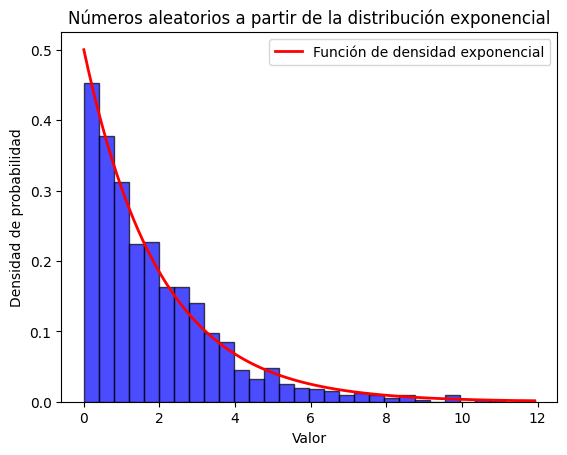

In [9]:
import numpy as np
import matplotlib.pyplot as plt
import random
import math

# Parámetro de intensidad
lambda_parametro = 0.5

def exponencial_transformada_inversa(lambda_param) :
    """
    Genera variables aleatorias exponenciales usando tel método de la transformada inversa
    """
    # Generamos un número aleatorio con distribución uniforme en [0,1)
    U = random.random()

    # La variable aleatoria que se obtiene a través de la transformada inversa
    X = -math.log(1-U) / lambda_param

    return X

# Tamaño de número aleatorios a generar
num_muestra = 1000

# Generar número aleatorios a partir de la distribución exponencial
numeros_aleatorios_exponenciales = [exponencial_transformada_inversa(lambda_parametro) for _ in range(num_muestra)]

# Histograma de los números aleatorios
plt.hist(numeros_aleatorios_exponenciales, bins=30, density=True, alpha=0.7, color='blue', edgecolor='black')

# Gráficar la función de densidad exponencial teórica y comparar
x = np.linspace(0, max(numeros_aleatorios_exponenciales), 100)
pdf = lambda_parametro * np.exp(-lambda_parametro * x)
plt.plot(x, pdf, 'r-', lw=2, label='Función de densidad exponencial')

plt.title('Números aleatorios a partir de la distribución exponencial')
plt.xlabel('Valor')
plt.ylabel('Densidad de probabilidad')
plt.legend(loc='best')

plt.show()

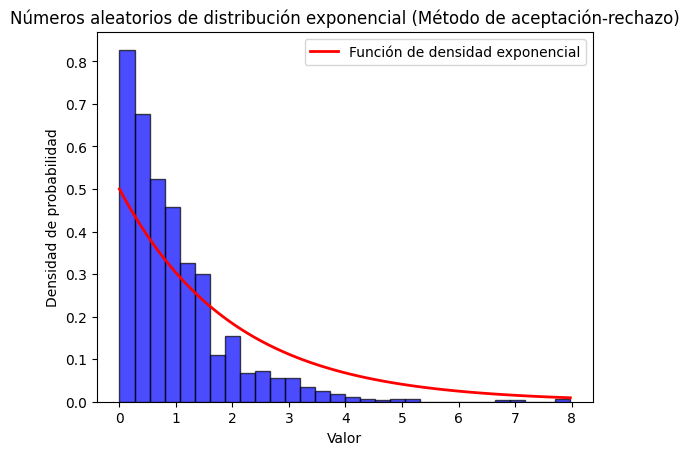

In [11]:
# Parámetro de intensidad
lambda_parametro = 0.5

# Valor máximo de la distribución exponencial (Elegido para asegurar la aceptación)
M = 1 / lambda_parametro

def exponencial_aceptacion(lambda_parametro, M) :
    while True:
      # Generar un número aleatorio a partir de la distribución exponencial con el parámetro lambda_param
      x = -math.log(1-random.random()) / lambda_parametro

      # Generar un número aleatorio uniforme para aceptación/rechazo
      u = random.random()

      # Aceptar el valor generado si cae por debajo de la curva exponencial
      if u < lambda_parametro * math.exp(-lambda_parametro * x) / M :
        return x

# Número de números aleatorios a generar
num_muestra = 1000

# Generar números aleatorios a partir de la distribución exponencial utilizando el método de aceptación-rechazo
numeros_exponencial = [exponencial_aceptacion(lambda_parametro, M) for _ in range(num_muestra)]

# Crear un histograma
plt.hist(numeros_exponencial, bins=30, density=True, alpha=0.7, color='blue', edgecolor='black')

# Gráficar la función de densidad exponencial teórica y comparar
x = np.linspace(0, max(numeros_exponencial), 100)
pdf = lambda_parametro * np.exp(-lambda_parametro * x)
plt.plot(x, pdf, 'r-', lw=2, label='Función de densidad exponencial')

plt.title('Números aleatorios de distribución exponencial (Método de aceptación-rechazo)')
plt.xlabel('Valor')
plt.ylabel('Densidad de probabilidad')
plt.legend(loc='best')

plt.show()

Text(1.0, 0.03, 'Aceptación')

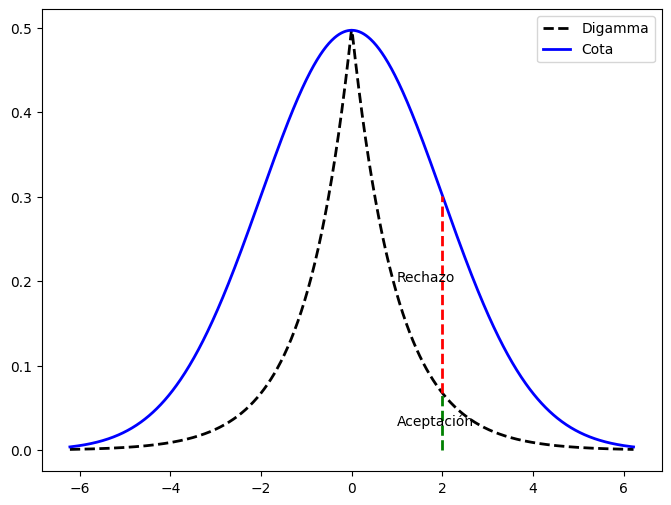

In [15]:
import scipy.stats as stats
import pandas as pd

dg = stats.dgamma(a=1) #Distribución digamma
norm = stats.norm(loc=0, scale=2) #Distribución normal

# Generar muestras para PDF
x = np.linspace(min(dg.ppf(0.001), norm.ppf(0.001)),
                max(dg.ppf(0.999), norm.ppf(0.999)), 1000)
dg_muestra = dg.pdf(x)
norm_muestra = norm.pdf(x)

# Encontrar la constante de escala para la envolvente
M = max(dg_muestra / norm_muestra)

# Gráficas
df = pd.DataFrame({'Digamma': dg_muestra, 'Cota': M * norm_muestra}, index=x)
ax = df.plot(style=['--','-'], color=['black', 'blue'],
             figsize=(8,6), linewidth=2.0)
ax.plot((2,2), (0, dg.pdf(2)), 'g--', linewidth=2.0)
ax.plot((2,2), (dg.pdf(2), M * norm.pdf(2)), 'r--', linewidth=2.0)
ax.text(1.0, 0.20, 'Rechazo')
ax.text(1.0, 0.03, 'Aceptación')

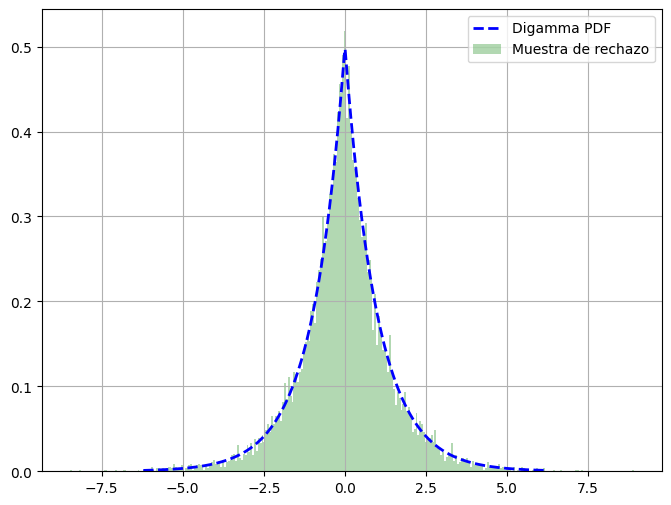

In [17]:
def muestra_de_rechazo():
  while True:
    x = np.random.normal(0,2)
    cota = M * norm.pdf(x)
    p = np.random.uniform(0,cota)
    if p <= dg.pdf(x):
      return x

# Muestras de generación a partir del algoritmo de muestreo de rechazo
muestras = [muestra_de_rechazo() for x in range(10000)]

# Trazar histograma frente a la función de densidad de probabilidad objetivo
df['Digamma'].plot(color='blue', style='--', figsize=(8,6), linewidth=2.0)
pd.Series(muestras).hist(bins=300, density=True, color='green',
                         alpha=0.3, linewidth=0.0)
plt.legend(['Digamma PDF', 'Muestra de rechazo'])